# 血糖记录与复诊准备：模拟产品行为分析

analysis-1.0｜2026-09-17｜方案 0.3、应用 0.2.1 的分析阶段交付。

**这里的使用者、业务关系与操作事件全部是 simulated（程序按公开假设生成的虚构行为）。统计用于检验分析流程和提出待验证问题，不证明真实需求、留存、产品收益或临床效果。** 没有真实患者资料、模型调用、真人研究或医学审核；原有 demo 日志不计入样本。

基准情景覆盖 400 名模拟使用者和 90 天，清洗前为 17,168 条操作事件，清洗后保留 16,887 条。公开版内嵌静态图表，便于 GitHub 预览。本地运行可生成原有的交互式图表。

建议先读各节解释和图表，再读代码。全部代码依次运行可重新生成相同原始数据、清洗结果与指标；原始文件若与重跑结果不同，程序停止而不覆盖。运行入口见上级 README；run_analysis.py 默认在两个全新 Python 内核中各运行一遍，实际重跑记录另存 outputs/reproducibility.json。

本 Notebook 回答：从填写到保存有哪些去向；记录能否复用于材料；回访做什么；草稿补全、核对和失败恢复如何观察；哪些建议仍需真实任务验证。完整参数见 config.json，生成前约定见《分析约定.md》，指标实现在 metrics.py，生成器在 generate.py。

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, HTML
ROOT=Path.cwd()
if not (ROOT/'config.json').exists() and (ROOT/'analysis'/'config.json').exists():
    ROOT=ROOT/'analysis'
sys.path.insert(0,str(ROOT))
from generate import load_config, generate, write_dataset, json_bytes, jsonl_bytes, digest
from metrics import read_dataset, clean_events, analyze, audit_business, write_outputs
from checks import run_small_checks
OUT=ROOT/'outputs'
OUT.mkdir(exist_ok=True)
C=load_config(ROOT/'config.json')
pd.set_option('display.max_colwidth',90)
def percent(n,d):return '不可计算（分母为0）' if not d else f'{n/d:.1%}'
def table(df):
    display(HTML('<div style="overflow-x:auto">'+df.to_html(index=False,escape=True,
        na_rep='不可计算',border=0,float_format=lambda x:f'{x:.4f}')+'</div>'))
def say(s):display(Markdown(s))
def save_json(path,obj):path.write_bytes(json_bytes(obj))

## 1. 生成前确定的假设和观察口径

选择 400 名虚拟使用者、90 天，是为了让两条流程及 7/30 天观察不足同时出现，且可在个人电脑反复运行。进入日期均匀分散；后续会话概率随进入时长衰减；60% 被设为可能有复诊准备机会，其余可独立记录。**这些是假设，不是从 81 条 demo 开发操作估计的人群规律。**

生成器按照“已有记录 → 选择范围与记录 → 生成版本 → 本人确认 → 可选取用”推进。具体血糖值和自由文字不是本次行为分析所需，不生成，也不进入事件；单独业务关系表只保存状态、未知总数、虚构测量日期及版本等验证关联所需元数据，不是可导回网页的临床记录集。操作时间单独生成，不从测量日期回填使用日期。

高缺项倾向人为提高草稿概率，同时降低进入核对概率；两者若在结果中有关联，主要来源之一就是这个设定。回访、准备机会、确认/取用和重试概率也直接影响结果。潜在倾向与机会表仅存于 simulation_truth.json，不充当产品已观测画像。

窗口以 Asia/Shanghai 自然日划分，左闭右开。回访以首次手动有效保存（包括由草稿补全）的日期为 D0；次日为 D1，7/30 日为 D1—7/D1—30 **累计窗口回访**，不是“恰好第 7/30 日留存”。D0 反复操作不计回访。只有完整经历窗口的人进入分母，其他为观察不足。窗口不是医学测量或复诊频次建议。

In [2]:
end=pd.Timestamp(C['start_local'])+pd.Timedelta(days=C['days'])
table(pd.DataFrame([
 {'项目':'来源','冻结值':'simulated；demo 不合并'},
 {'项目':'冻结时刻UTC','冻结值':C['frozen_at']},
 {'项目':'规模 / 种子','冻结值':f"{C['users']}人 / {C['seed']}"},
 {'项目':'本地观察窗','冻结值':f"{C['start_local']} 00:00 至 {end.date()} 00:00（不含）"},
 {'项目':'日会话基础概率','冻结值':str(C['daily_return_probability'])+'，随进入时长衰减'},
 {'项目':'保存失败 / 失败后重试','冻结值':f"{C['save_failure_probability']} / {C['save_retry_probability']}"},
 {'项目':'可能有准备机会的概率','冻结值':str(C['has_prep_opportunity_probability'])},
 {'项目':'生成后本人确认概率','冻结值':str(C['confirm_probability'])},
 {'项目':'预定参数变化','冻结值':str(C['sensitivity'])}
]))

项目,冻结值
来源,simulated；demo 不合并
冻结时刻UTC,2026-09-17T15:10:25.243311+00:00
规模 / 种子,400人 / 20260917
本地观察窗,2026-06-01 00:00 至 2026-08-30 00:00（不含）
日会话基础概率,0.13，随进入时长衰减
保存失败 / 失败后重试,0.1 / 0.7
可能有准备机会的概率,0.6
生成后本人确认概率,0.82
预定参数变化,"{'less_return': {'daily_return_probability': 0.07}, 'more_write_failure': {'save_failure_probability': 0.2}}"


## 2. 先手工复核小例子，再跑完整数据

三名使用者、10 天窗口。U1 在 D0 有效新增，D1 新增草稿（失败后重试保存），用两条记录生成 p1/v1、确认并复制；D2 编辑补全草稿，v1 失效，再生成 p1/v2、确认并请求打印。U2 有一次只开始的新增和一次有效新增，p2 首次生成失败、后来成功展示但未确认。U3 在第 9 天才完成有效新增，后续观察不足。

手工预期：5 次新增，4 次核对/请求/保存，3 次直接有效保存；草稿补全属于编辑，不回填为第四次有效新增。2 次准备中 1 次曾完成；3 个摘要版本有 2 个确认，其中 1 个失效。D1 保存回访为 1/2，另外 1 人观察不足；D1 有效新增为 0/2，因为那次保存只是草稿。D30 没有完整分母，应显示不可计算。预期先写成固定断言，不以程序结果反推。

In [3]:
manual_table,small_checks=run_small_checks()
table(manual_table.rename(columns={'check':'核对项','hand_expected':'手工预期','actual':'实际计算','passed':'一致'}))
say(f"手工关键口径 **{small_checks['manual_checks']} 项一致**；另用 {small_checks['small_generated_users']} 名使用者、"
    f"{small_checks['small_generated_events']} 条事件做小规模生成和关联检查，通过后才继续。")
save_json(OUT/'manual_checks.json',json.loads(manual_table.to_json(orient='records',force_ascii=False)))

核对项,手工预期,实际计算,一致
新增漏斗：开始/核对/请求/保存/有效,"[5, 4, 4, 4, 3]","[5, 4, 4, 4, 3]",True
准备任务：开始/请求/成功/确认/取用,"[2, 2, 2, 1, 1]","[2, 2, 2, 1, 1]",True
版本：生成/展示/确认/复制/打印请求,"[3, 3, 2, 1, 1]","[3, 3, 2, 1, 1]",True
曾确认版本/失效确认版本/当前确认版本,"[2, 1, 1]","[2, 1, 1]",True
保存失败：恢复数/失败尝试数/恢复为草稿,"[1, 1, 1]","[1, 1, 1]",True
首次草稿/后来补全/7天内补全,"[1, 1, 1]","[1, 1, 1]",True
D1 保存回访 n/N/截尾,"[1, 2, 1]","[1, 2, 1]",True
D1 有效新增回访 n/N,"[0, 2]","[0, 2]",True
D30 完整观察人数,0,0,True
脏行隔离且有效事件不丢失,"[3, 51]","[3, 51]",True


手工关键口径 **10 项一致**；另用 8 名使用者、164 条事件做小规模生成和关联检查，通过后才继续。

## 3. 完整生成、清洗与业务关联检查

数据质量练习采用“保留原有效事件，追加坏行，再打乱顺序”：约 1.5% 完全重复行、12 行坏时间、8 行缺使用者、8 行悬空记录。清洗依据字段白名单、时间窗和业务关系隔离，不读注入账本猜补数据；之后才用生成清单核对数量和哈希（内容指纹）。

不同 event_id 的重复核对/展示是模拟操作，应保留；相同 event_id 的完全重复行才去重。保存失败、生成失败是产品行为结果，必须保留。本练习保留了完整原链，能无损恢复是注入方式的结果，不意味着真实漏日志也能恢复。

In [4]:
generated=generate(C,'baseline')
manifest=write_dataset(generated,ROOT/'raw'/'baseline')
data=read_dataset(ROOT/'raw'/'baseline')
clean,quarantine,cleaning=clean_events(data)
assert len(clean)==manifest['expected_clean_count']
assert digest(jsonl_bytes(clean))==manifest['pristine_event_hash']
audit=audit_business(clean,data)
result=analyze(clean,data['config'])
hashes=write_outputs(result,OUT/'baseline',cleaning,audit)
(OUT/'baseline'/'events_clean.jsonl').write_bytes(jsonl_bytes(clean))
(OUT/'baseline'/'events_quarantine.jsonl').write_bytes(jsonl_bytes(quarantine))
S,Q=result['summary'],result['quality']
table(pd.DataFrame([{'处理':'清洗前','行数':cleaning['raw_rows']},
 *[{'处理':k,'行数':v} for k,v in sorted(cleaning['reasons'].items())],
 {'处理':'清洗后保留','行数':cleaning['clean_rows']}]))
table(pd.DataFrame([
 {'对象':'虚拟使用者','数量':S['users']},
 {'对象':'独立记录 / 保存版本','数量':f"{S['unique_records']} / {audit['record_revisions']}"},
 {'对象':'准备任务 / 摘要版本','数量':f"{S['prep_tasks']} / {S['summary_versions']}"},
 {'对象':'跨准备复用的记录 / 来源引用','数量':f"{audit['records_used_in_multiple_preps']} / {audit['source_references']}"},
 {'对象':'来源不匹配 / 失效后取用','数量':f"{audit['unmatched_summary_sources']} / {audit['invalid_takeout_events']}"}
]))
assert S['users']==C['users']
say(f"实际得到 **{S['users']} 名虚拟使用者、{S['unique_records']} 条独立记录、{S['prep_tasks']} 次准备、"
    f"{S['summary_versions']} 个摘要版本**。{audit['records_used_in_multiple_preps']} 条记录用于不止一次准备，"
    f"核对 {audit['source_references']} 个来源版本引用。清洗保留 {S['save_failures']} 次保存失败和 "
    f"{S['generation_failures']} 次生成失败。")

处理,行数
清洗前,17168
exact_duplicate,253
invalid_time,12
missing_required,8
orphan_record,8
清洗后保留,16887


对象,数量
虚拟使用者,400
独立记录 / 保存版本,1176 / 1498
准备任务 / 摘要版本,333 / 261
跨准备复用的记录 / 来源引用,67 / 622
来源不匹配 / 失效后取用,0 / 0


实际得到 **400 名虚拟使用者、1176 条独立记录、333 次准备、261 个摘要版本**。67 条记录用于不止一次准备，核对 622 个来源版本引用。清洗保留 156 次保存失败和 169 次生成失败。

关联断言检查记录修改版本连续，来源在生成前已保存、属于同一使用者且为生成时版本，数量与来源状态相符；同一记录复用而不另造业务记录；生成请求与结果一一对应，每个保存尝试至多一次成功；确认和取用不发生在摘要失效之后；有影响的改动和同任务新版使旧版本失效。独立记录事件没有强加 prep_id。这验证数据内部一致性，不能替代浏览器或医学测试。

In [5]:
FONT='Microsoft YaHei, PingFang SC, Noto Sans CJK SC, sans-serif'
chart_files=[]
def show_chart(fig,name,title,height=500):
    fig.update_layout(title=dict(text=title+f"<br><sup>simulated｜观察窗 {C['start_local']}—{(end-pd.Timedelta(days=1)).date()}｜Asia/Shanghai</sup>",font=dict(size=19)),template='plotly_white',
        font=dict(family=FONT,size=13),height=height,
        margin=dict(l=65,r=35,t=110,b=75),legend=dict(orientation='h',y=-.18))
    path=OUT/f'{name}.html'
    fig.write_html(path,include_plotlyjs=True,config={'displayModeBar':False},div_id=name)
    display(HTML(fig.to_html(full_html=False,include_plotlyjs=True if not chart_files else False,
        config={'displayModeBar':False},div_id='nb-'+name)))
    chart_files.append(path.name)

## 4. 两条漏斗：成功保存与完成准备分开

新增漏斗单位是去重 attempt_id，分母为开始新增的尝试。保存成功含草稿；有效保存表示数值/单位可整理，不表示医学正常；编辑单列。准备漏斗单位是 prep_id：至少一次生成、至少一版本人确认。“可选取用”是复制成功或打印请求的并集，不要求两者都发生，不代表带去就诊。

每层以各自“开始”为分母，这是观察期内的累计到达；窗口末尾未完成可能是机会不足。没有退出事件，不能称为主动放弃。两流程单位不同，不可把两条柱子相减当流失人数。

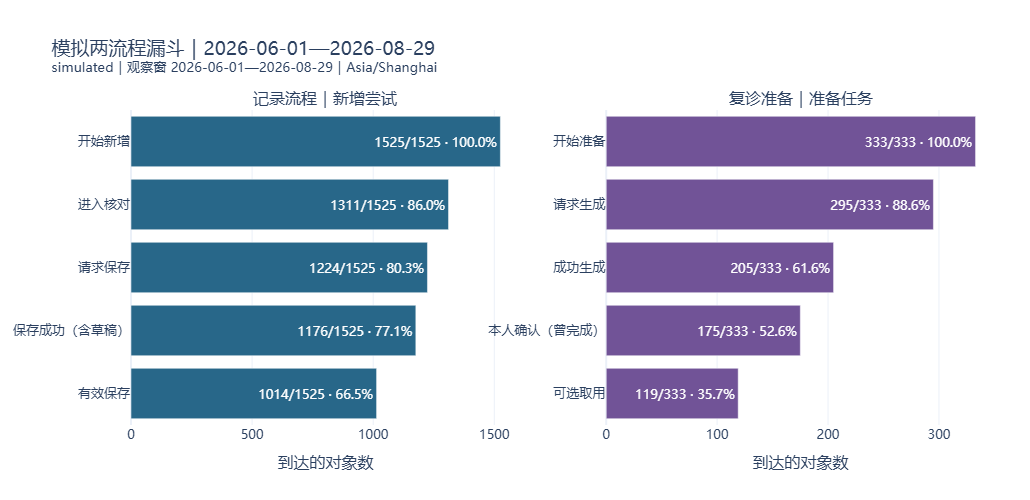

版本阶段,到达版本数,生成版本分母,比例
生成版本,261,261,1.0000
材料展示,261,261,1.0000
本人确认,209,261,0.8008
复制成功,126,261,0.4828
打印请求,25,261,0.0958


新增有效保存 **1014/1525（66.5%）**，另有 162 次草稿保存。编辑 404 次，其中 303 次保存为有效记录。准备曾完成 **175/333（52.6%）**，期末仍有当前有效确认版本的准备为 **119/333**。

按使用者看，观察窗内至少完成首条手动有效记录的是 **354/400**，分母为本情景所有已进入并同意的模拟编号，观察机会长短不同；其余不能一律称为填表失败。首次新增尝试直接有效与后来草稿补全再首次有效，也不是同一口径。

209 个曾确认摘要中，90 个随后失效。较少的期末有效数可能来自后续记录变化和重生成，是版本保护发挥作用的一种情况；不能断言已完成准备都失败，也不能把旧确认当作当前可取用。版本表的复制与打印是确认后的可重叠分支，不是先复制才打印。展示不证明认真阅读。

In [6]:
fig=make_subplots(rows=1,cols=2,subplot_titles=['记录流程｜新增尝试','复诊准备｜准备任务'])
for col,key,color in [(1,'record_funnel','#286789'),(2,'prep_funnel','#715397')]:
    f=result[key]
    fig.add_trace(go.Bar(x=f.numerator,y=f.stage,orientation='h',marker_color=color,
        text=[f'{n}/{d} · {percent(n,d)}' for n,d in zip(f.numerator,f.denominator)],
        textposition='auto',hovertemplate='%{y}<br>%{text}<extra></extra>',showlegend=False),row=1,col=col)
    fig.update_yaxes(autorange='reversed',row=1,col=col)
    fig.update_xaxes(title_text='到达的对象数',rangemode='tozero',row=1,col=col)
show_chart(fig,'01_funnels',f"模拟两流程漏斗｜{C['start_local']}—{(end-pd.Timedelta(days=1)).date()}")
table(result['version_funnel'].rename(columns={'stage':'版本阶段','numerator':'到达版本数','denominator':'生成版本分母','rate':'比例'}))
say(f"新增有效保存 **{S['new_valid']}/{S['new_attempts']}（{percent(S['new_valid'],S['new_attempts'])}）**，"
    f"另有 {S['new_draft']} 次草稿保存。编辑 {S['edit_attempts']} 次，其中 {Q['edit_valid']} 次保存为有效记录。"
    f"准备曾完成 **{S['completed_preps']}/{S['prep_tasks']}（{percent(S['completed_preps'],S['prep_tasks'])}）**，"
    f"期末仍有当前有效确认版本的准备为 **{S['current_completed_preps']}/{S['prep_tasks']}**。")
say(f"按使用者看，观察窗内至少完成首条手动有效记录的是 **{S['first_valid_users']}/{C['users']}**，"
    "分母为本情景所有已进入并同意的模拟编号，观察机会长短不同；其余不能一律称为填表失败。"
    "首次新增尝试直接有效与后来草稿补全再首次有效，也不是同一口径。")
say(f"{Q['confirmed_versions']} 个曾确认摘要中，{Q['confirmed_invalidated']} 个随后失效。"
    "较少的期末有效数可能来自后续记录变化和重生成，是版本保护发挥作用的一种情况；"
    "不能断言已完成准备都失败，也不能把旧确认当作当前可取用。"
    "版本表的复制与打印是确认后的可重叠分支，不是先复制才打印。展示不证明认真阅读。")

## 5. 分类回访：完整观察窗口作分母

分母为首次手动有效保存后已完整经历窗口的虚拟使用者；分子为窗口中发生至少一次指定行为的人。保存回访含草稿和编辑；有效新增要求另一条记录的 mode=create、status=valid。历史展示含保存后自动跳转，不能叫主动查阅。开始/完成准备分别计，不将无复诊需求解释为记录失败。行为可重叠，比例不能相加。

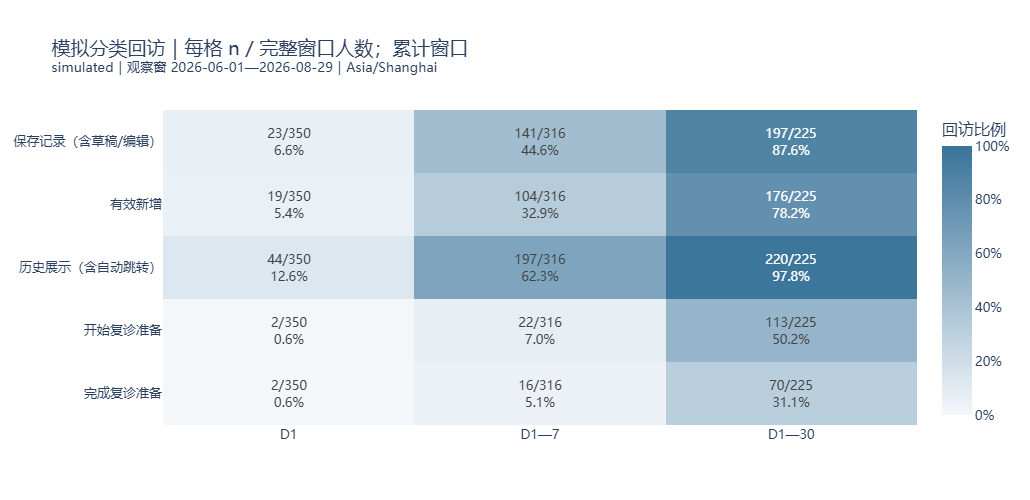

行为,窗口天数,回访人数,完整分母,观察不足,比例
保存记录（含草稿/编辑）,1,23,350,4,0.0657
有效新增,1,19,350,4,0.0543
历史展示（含自动跳转）,1,44,350,4,0.1257
开始复诊准备,1,2,350,4,0.0057
完成复诊准备,1,2,350,4,0.0057
保存记录（含草稿/编辑）,7,141,316,38,0.4462
有效新增,7,104,316,38,0.3291
历史展示（含自动跳转）,7,197,316,38,0.6234
开始复诊准备,7,22,316,38,0.0696
完成复诊准备,7,16,316,38,0.0506


7 日保存回访 **141/316**，有效新增回访 **104/316**；差异包括草稿与编辑。历史展示为 197/316，生成器在回访会话中也安排历史展示，该比例直接受会话设定和自动跳转影响。

准备机会仅对部分人开放，并常在较晚日期出现；短窗准备回访不能作为一般留存优劣排名。没有使用事件不意味着没有测血糖、没有复诊需求或依从性差。

In [7]:
ret=result['retention'];labels=list(ret.behavior.drop_duplicates());windows=[1,7,30]
matrix=[];texts=[]
for behavior in labels:
    g=ret[ret.behavior.eq(behavior)].set_index('window')
    matrix.append([None if pd.isna(g.loc[w,'rate']) else float(g.loc[w,'rate']) for w in windows])
    texts.append([f"{int(g.loc[w,'numerator'])}/{int(g.loc[w,'denominator'])}<br>{percent(g.loc[w,'numerator'],g.loc[w,'denominator'])}" for w in windows])
fig=go.Figure(go.Heatmap(z=matrix,x=['D1','D1—7','D1—30'],y=labels,text=texts,texttemplate='%{text}',
    colorscale=[[0,'#f4f8fb'],[1,'#397399']],zmin=0,zmax=1,colorbar=dict(title='回访比例',tickformat='.0%'),
    hovertemplate='%{y}<br>%{x}<br>%{text}<extra></extra>'))
fig.update_yaxes(autorange='reversed')
show_chart(fig,'02_returns','模拟分类回访｜每格 n / 完整窗口人数；累计窗口',550)
table(ret.rename(columns={'behavior':'行为','window':'窗口天数','numerator':'回访人数','denominator':'完整分母','censored':'观察不足','rate':'比例'}))
r7=ret[ret.window.eq(7)].set_index('behavior')
say(f"7 日保存回访 **{int(r7.loc['保存记录（含草稿/编辑）','numerator'])}/{int(r7.iloc[0].denominator)}**，"
    f"有效新增回访 **{int(r7.loc['有效新增','numerator'])}/{int(r7.iloc[0].denominator)}**；"
    f"差异包括草稿与编辑。历史展示为 {int(r7.loc['历史展示（含自动跳转）','numerator'])}/{int(r7.iloc[0].denominator)}，"
    "生成器在回访会话中也安排历史展示，该比例直接受会话设定和自动跳转影响。")
say("准备机会仅对部分人开放，并常在较晚日期出现；短窗准备回访不能作为一般留存优劣排名。"
    "没有使用事件不意味着没有测血糖、没有复诊需求或依从性差。")

## 6. 信息质量、分群和操作负担

只用当前可观察的“首次/后续新增尝试”和“首次核对未知合计”分群；每组有效/草稿/未保存比例以该组新增尝试数为分母。没有核对事件的单列，不假设零缺项。2—5 项未知并非临床风险高；保留未知可以是正确处理。生成器没有模拟在核对页反复改字段，分组与草稿关系尤其受设定影响。

草稿补全按 record_id 跟踪后续 valid 版本；再报完整 7 天内转化（首存当日至 D7），不把晚进入者一律当未改善。有效仅说明数值/单位确认，其他字段仍可未知。次数是负担代理量，不是精确活动耗时或理解程度。

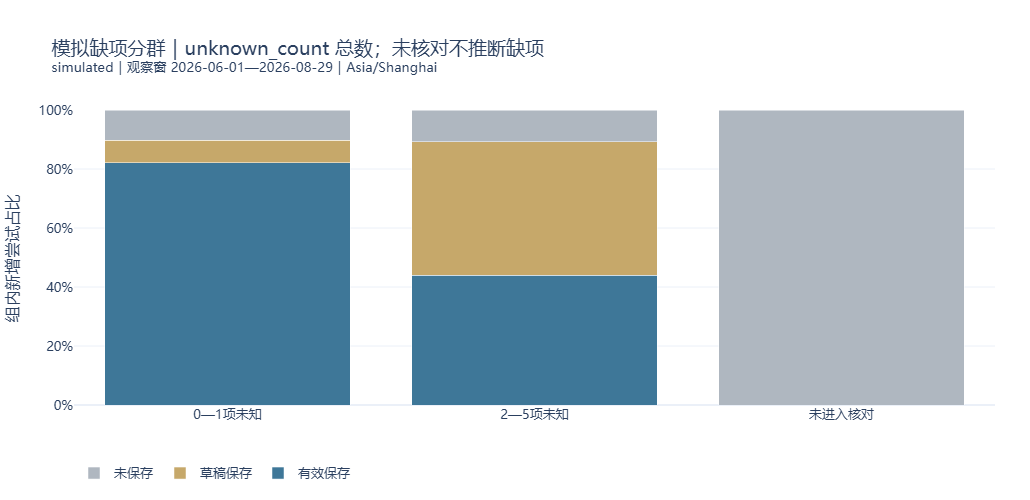

分群依据,组别,新增尝试,有效保存,草稿保存,未保存,有效保存率,平均核对次数/尝试
首次核对缺项,0—1项未知,1145,941,87,117,0.8218,1.2000
首次核对缺项,2—5项未知,166,73,75,18,0.4398,1.1627
首次核对缺项,未进入核对,214,0,0,214,0.0000,0.0000
新增经验,后续新增尝试,1133,755,105,273,0.6664,1.0229
新增经验,首次新增尝试,392,259,57,76,0.6607,1.0408


指标,分子,分母,单位,比例
首次草稿后来转有效（整窗）,51,162,独立草稿记录,31.5%
首存日—D7转有效（完整观察）,19,137,完整7天观察的草稿,13.9%
核对超过一次,313,1667,有核对的新增/编辑尝试,18.8%
至少一次展示来源,112,261,生成摘要版本,42.9%


首次草稿 162 条，整窗补全 51 条；完整 7 天口径为 **19/137**，另有 25 条观察不足。全部新增/编辑尝试平均核对 1.03 次、保存请求 0.86 次；每次开始准备平均生成 0.78 个版本（含零版本任务）。

29/261 个摘要选中来源含草稿；跨版本累计 30 个草稿引用不纳入有效数，同一草稿可重复引用，不是独立条数。unknown_count 不能拆成各字段缺失率；不借模拟器内部字段伪装成网页已有观测能力。

In [8]:
seg=result['segments'];g=seg[seg.dimension.eq('首次核对缺项')].copy()
fig=go.Figure()
for field,label,color in [('valid','有效保存','#3e7798'),('draft','草稿保存','#c6a86a'),('not_saved','未保存','#afb7c0')]:
    fig.add_trace(go.Bar(x=g['group'],y=g[field]/g.attempts,name=label,marker_color=color,
        customdata=np.column_stack([g[field],g.attempts]),
        hovertemplate='%{x}<br>'+label+' %{customdata[0]}/%{customdata[1]}<extra></extra>'))
fig.update_layout(barmode='stack')
fig.update_yaxes(title_text='组内新增尝试占比',tickformat='.0%',range=[0,1])
show_chart(fig,'03_information','模拟缺项分群｜unknown_count 总数；未核对不推断缺项',510)
table(seg.rename(columns={'dimension':'分群依据','group':'组别','attempts':'新增尝试','valid':'有效保存','draft':'草稿保存','not_saved':'未保存','valid_rate':'有效保存率','reviews_mean':'平均核对次数/尝试'}))
qt=pd.DataFrame([
 {'指标':'首次草稿后来转有效（整窗）','分子':Q['drafts_converted'],'分母':Q['first_drafts'],'单位':'独立草稿记录'},
 {'指标':'首存日—D7转有效（完整观察）','分子':Q['draft_7_converted'],'分母':Q['draft_7_eligible'],'单位':'完整7天观察的草稿'},
 {'指标':'核对超过一次','分子':Q['repeated_review_attempts'],'分母':Q['reviewed_attempts'],'单位':'有核对的新增/编辑尝试'},
 {'指标':'至少一次展示来源','分子':Q['source_viewed_versions'],'分母':Q['summary_versions'],'单位':'生成摘要版本'}])
qt['比例']=[percent(n,d) for n,d in zip(qt['分子'],qt['分母'])]
table(qt)
summary_table=result['summaries']
say(f"首次草稿 {Q['first_drafts']} 条，整窗补全 {Q['drafts_converted']} 条；完整 7 天口径为 "
    f"**{Q['draft_7_converted']}/{Q['draft_7_eligible']}**，另有 {Q['first_drafts']-Q['draft_7_eligible']} 条观察不足。"
    f"全部新增/编辑尝试平均核对 {Q['reviews_mean']:.2f} 次、保存请求 {Q['requests_mean']:.2f} 次；"
    f"每次开始准备平均生成 {Q['prep_versions_mean']:.2f} 个版本（含零版本任务）。")
say(f"{int(summary_table.drafts.gt(0).sum())}/{len(summary_table)} 个摘要选中来源含草稿；"
    f"跨版本累计 {int(summary_table.drafts.sum())} 个草稿引用不纳入有效数，同一草稿可重复引用，不是独立条数。"
    "unknown_count 不能拆成各字段缺失率；不借模拟器内部字段伪装成网页已有观测能力。")

## 7. 失败、恢复与未完成

保存分母为失败 attempt_id，分子为同尝试失败后成功保存；恢复为草稿/有效分别报告。生成分母为失败 prep_id，分子为同任务失败后有生成成功；普通失败与显式测试注入分开，同任务可能进入两组，不可合并分母。生成恢复不要求后来确认摘要。

普通生成失败原因粗，可能是条件不足或存储/格式等问题，只能在生成机制中解释构成，不能把事件代码扩解为精确定位。没有后续成功称“观察到未恢复”，不认定主动放弃。复制失败和打印请求不冒充纸面交付。

本生成器在一次即时重试中不改变选取，若没有有效记录，两次请求都会失败；没有成功生成过版本的准备也没有模拟日后回到同任务重新选取。故普通生成恢复率明显受这一结构限制，不是现有产品不能恢复。范围、草稿和机会不足均可能影响结果，不把普通失败率直接叫系统故障率。

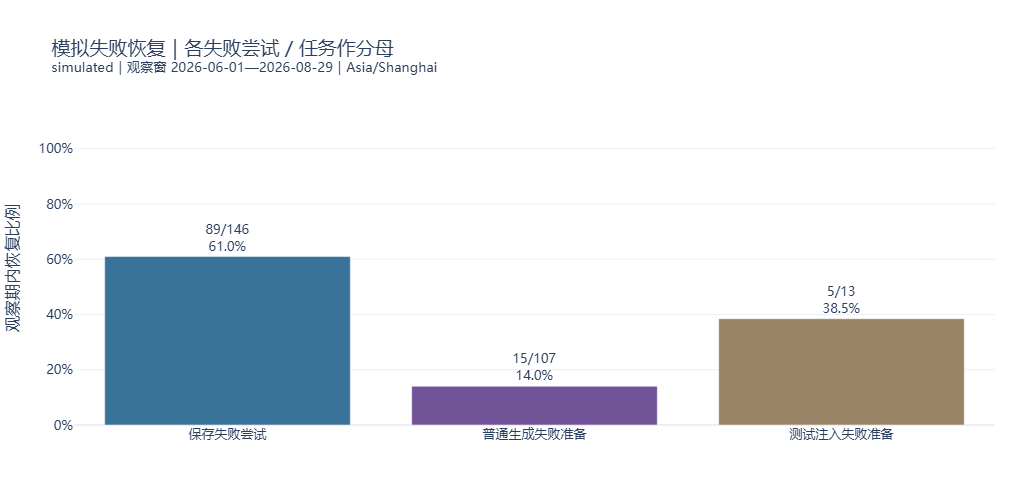

失败对象,后来恢复,失败对象数,恢复率,恢复为有效,恢复为草稿
保存失败尝试,89,146,0.6096,79.0000,10.0000
普通生成失败准备,15,107,0.1402,不可计算,不可计算
测试注入失败准备,5,13,0.3846,不可计算,不可计算


保存请求失败 156/1654 次；生成请求失败 169/430 次。请求口径不同于对象口径。复制失败 4 次；打印请求 25 次，仅说明请求。重复展示额外 27 次，不膨胀为新完成任务。

保存失败 146 次尝试中，89 次恢复，其中有效 79、草稿 10。重试倾向预设为0.70、最多一次即时重试，是生成假设，不是界面恢复体验的实测评价。

In [9]:
recovery=result['recovery']
fig=go.Figure(go.Bar(x=recovery.flow,y=recovery['rate'],marker_color=['#397399','#715397','#998467'],
    text=[f'{n}/{d}<br>{percent(n,d)}' for n,d in zip(recovery.numerator,recovery.denominator)],
    textposition='outside',hovertemplate='%{x}<br>%{text}<extra></extra>'))
fig.update_yaxes(title_text='观察期内恢复比例',tickformat='.0%',range=[0,1.14])
show_chart(fig,'04_recovery','模拟失败恢复｜各失败尝试 / 任务作分母',500)
table(recovery.rename(columns={'flow':'失败对象','numerator':'后来恢复','denominator':'失败对象数','rate':'恢复率','valid':'恢复为有效','draft':'恢复为草稿'}))
e=result['events']
repeated_views=int(e[e.event_type.eq('summary_viewed')].shape[0]-summary_table.viewed.sum())
say(f"保存请求失败 {S['save_failures']}/{S['save_requests']} 次；生成请求失败 {S['generation_failures']}/{S['generation_requests']} 次。"
    f"请求口径不同于对象口径。复制失败 {int(e.event_type.eq('copy_failed').sum())} 次；"
    f"打印请求 {int(e.event_type.eq('print_requested').sum())} 次，仅说明请求。"
    f"重复展示额外 {repeated_views} 次，不膨胀为新完成任务。")
save_failed=recovery.iloc[0]
say(f"保存失败 {int(save_failed.denominator)} 次尝试中，{int(save_failed.numerator)} 次恢复，"
    f"其中有效 {int(save_failed.valid)}、草稿 {int(save_failed.draft)}。"
    "重试倾向预设为0.70、最多一次即时重试，是生成假设，不是界面恢复体验的实测评价。")

## 8. 只做两次预定参数变化

预先指定日会话基础概率从 0.13 降到 0.07；保存失败概率从 0.10 升到 0.20。每次只改一个参数，种子、人数和窗口相同。保留独立原件和检查，不根据结果反复改概率。分支会消耗不同随机数，所以不是严格配对实验，差值不是改版收益。

本节检查对假设的敏感程度。比例改变提示需要实测相应行为；即便方向不变，也只针对这两个设置，不证明普遍规律。

In [10]:
scenarios={'baseline':(result,cleaning,audit)}
scenario_checks={'baseline':audit}
for name in C['sensitivity']:
    sim=generate(C,name)
    man=write_dataset(sim,ROOT/'raw'/name)
    source=read_dataset(ROOT/'raw'/name)
    rows,bad,report=clean_events(source)
    assert len(rows)==man['expected_clean_count']
    assert digest(jsonl_bytes(rows))==man['pristine_event_hash']
    business=audit_business(rows,source)
    metrics=analyze(rows,source['config'])
    write_outputs(metrics,OUT/name,report,business)
    scenarios[name]=(metrics,report,business)
    scenario_checks[name]=business
comparison=[]
for name,(m,cl,au) in scenarios.items():
    sm=m['summary'];rr=m['retention']
    get7=lambda label:rr[rr.window.eq(7)&rr.behavior.eq(label)].iloc[0]
    sav=get7('保存记录（含草稿/编辑）');new=get7('有效新增')
    comparison.append(dict(scenario=name,change='无' if name=='baseline' else str(C['sensitivity'][name]),
        events=sm['events'],new_attempts=sm['new_attempts'],valid_rate=sm['new_valid']/sm['new_attempts'],
        saved_7_n=int(sav.numerator),eligible_7=int(sav.denominator),saved_7_rate=float(sav.rate),
        new_7_n=int(new.numerator),new_7_rate=float(new.rate),prep_tasks=sm['prep_tasks'],
        ever_completed=sm['completed_preps'],current_completed=sm['current_completed_preps'],
        failed_attempts=int(m['recovery'].iloc[0].denominator),recovery_rate=float(m['recovery'].iloc[0].rate)))
sensitivity=pd.DataFrame(comparison)
save_json(OUT/'sensitivity.json',json.loads(sensitivity.to_json(orient='records',force_ascii=False)))
scenario_labels={'baseline':'基准','less_return':'降低日会话概率','more_write_failure':'提高保存失败概率'}
view=sensitivity.copy()
view['scenario']=view.scenario.map(scenario_labels)
table(view[['scenario','new_attempts','valid_rate','saved_7_n','eligible_7','saved_7_rate','new_7_n','new_7_rate']].rename(columns={
 'scenario':'情景','new_attempts':'新增尝试','valid_rate':'新增有效率','saved_7_n':'7日保存回访','eligible_7':'7日完整分母','saved_7_rate':'7日保存率','new_7_n':'7日有效新增','new_7_rate':'7日新增率'}))
table(view[['scenario','prep_tasks','ever_completed','current_completed','failed_attempts','recovery_rate']].rename(columns={
 'scenario':'情景','prep_tasks':'准备数','ever_completed':'曾完成','current_completed':'当前完成','failed_attempts':'保存失败尝试','recovery_rate':'保存恢复率'}))
base=sensitivity.iloc[0];low=sensitivity[sensitivity.scenario.eq('less_return')].iloc[0]
fail=sensitivity[sensitivity.scenario.eq('more_write_failure')].iloc[0]
say(f"降低会话参数时，7 日有效新增回访由 {base.new_7_rate:.1%} 变为 {low.new_7_rate:.1%}，"
    f"分母由 {int(base.eligible_7)} 变为 {int(low.eligible_7)}；提高写入失败参数时，新增有效率由 "
    f"{base.valid_rate:.1%} 变为 {fail.valid_rate:.1%}，失败尝试由 {int(base.failed_attempts)} 变为 {int(fail.failed_attempts)}。"
    "指标受人为参数和随机路径影响，不能作为真实留存或故障成本预测。"
    "分开流程、单列观察不足、展示不等于意图和失效版本单列，在三个情景都继续适用。")
say(f"提高失败概率的情景仍出现 {int(fail.ever_completed)} 次曾确认准备，基准为 {int(base.ever_completed)} 次。"
    "这个反向变动保留原样；行为分支改变了后续随机路径，不能断言失败会促进准备，"
    "也不据此重调参数。若要估计真实影响，需要真实采集与合适的实验设计。")

情景,新增尝试,新增有效率,7日保存回访,7日完整分母,7日保存率,7日有效新增,7日新增率
基准,1525,0.6649,141,316,0.4462,104,0.3291
降低日会话概率,1093,0.6478,79,297,0.2660,59,0.1987
提高保存失败概率,1487,0.6342,134,313,0.4281,94,0.3003


情景,准备数,曾完成,当前完成,保存失败尝试,保存恢复率
基准,333,175,119,146,0.6096
降低日会话概率,324,151,112,98,0.6122
提高保存失败概率,336,186,125,293,0.5666


降低会话参数时，7 日有效新增回访由 32.9% 变为 19.9%，分母由 316 变为 297；提高写入失败参数时，新增有效率由 66.5% 变为 63.4%，失败尝试由 146 变为 293。指标受人为参数和随机路径影响，不能作为真实留存或故障成本预测。分开流程、单列观察不足、展示不等于意图和失效版本单列，在三个情景都继续适用。

提高失败概率的情景仍出现 186 次曾确认准备，基准为 175 次。这个反向变动保留原样；行为分支改变了后续随机路径，不能断言失败会促进准备，也不据此重调参数。若要估计真实影响，需要真实采集与合适的实验设计。

## 9. 三项值得后续验证的改进

以下是验证候选，本批没有改网页或证明收益。优先做小任务和文案比较，不因模拟比例高低增加大功能。

In [11]:
sg=result['segments'].set_index(['dimension','group'])
lo=sg.loc[('首次核对缺项','0—1项未知')];hi=sg.loc[('首次核对缺项','2—5项未知')]
recommendations=[
 {'候选':'把草稿已保存与保留未知的下一步解释放在同处，先测试文案',
  '模拟现象':f"高缺项组有效新增 {int(hi.valid)}/{int(hi.attempts)}；低缺项组 {int(lo.valid)}/{int(lo.attempts)}。完整7天草稿补全 {Q['draft_7_converted']}/{Q['draft_7_eligible']}。",
  '其他解释':'草稿、缺项与核对倾向本来就共同设定；也可能材料不全或无补全机会，不一定界面难懂。',
  '最小验证':'同组虚构缺项记录比较现有/候选文案，观察独立保存草稿、找到编辑、正确保留未知；记录误填、核对次数与求助。',
  '边界':'不强制猜字段，不用默认值提高有效率；valid不表示医学正常。'},
 {'候选':'复用现有保留输入和重试入口，测试保存失败反馈是否易懂',
  '模拟现象':f"{int(save_failed.denominator)} 次失败尝试中恢复 {int(save_failed.numerator)}，未观察到恢复 {int(save_failed.denominator-save_failed.numerator)}。",
  '其他解释':'主要受0.70重试概率影响；未恢复也可能窗口终止，不能认定主动退出。',
  '最小验证':'明确为测试注入，检查能否发现未保存、原输入仍在、重试只留一条；按attempt_id看恢复与重复成功。',
  '边界':'写入回读前不报成功；重复点击不另造记录，不跳过核对。'},
 {'候选':'要研究回来查记录，先为history_viewed增加有限的导航来源枚举',
  '模拟现象':f"7日历史展示 {int(r7.loc['历史展示（含自动跳转）','numerator'])}/{int(r7.iloc[0].denominator)}，含保存后跳转，当前不能回答主动查阅人数。",
  '其他解释':'自动跳转、点击入口或刷新都可能造成展示，高展示率不证明查阅价值。',
  '最小验证':'另行修改约定后记录保存后跳转/点击历史入口/其他等来源；受控任务核对点击与事件，再看有入口点击的历史展示回访。旧日志保持未知，不回填。',
  '边界':'不记录数值、备注、正文；点击仍不证明理解，不暗加现有数据没有的字段。'}]
table(pd.DataFrame(recommendations))
save_json(OUT/'recommendations.json',recommendations)

候选,模拟现象,其他解释,最小验证,边界
把草稿已保存与保留未知的下一步解释放在同处，先测试文案,高缺项组有效新增 73/166；低缺项组 941/1145。完整7天草稿补全 19/137。,草稿、缺项与核对倾向本来就共同设定；也可能材料不全或无补全机会，不一定界面难懂。,同组虚构缺项记录比较现有/候选文案，观察独立保存草稿、找到编辑、正确保留未知；记录误填、核对次数与求助。,不强制猜字段，不用默认值提高有效率；valid不表示医学正常。
复用现有保留输入和重试入口，测试保存失败反馈是否易懂,146 次失败尝试中恢复 89，未观察到恢复 57。,主要受0.70重试概率影响；未恢复也可能窗口终止，不能认定主动退出。,明确为测试注入，检查能否发现未保存、原输入仍在、重试只留一条；按attempt_id看恢复与重复成功。,写入回读前不报成功；重复点击不另造记录，不跳过核对。
要研究回来查记录，先为history_viewed增加有限的导航来源枚举,7日历史展示 197/316，含保存后跳转，当前不能回答主动查阅人数。,自动跳转、点击入口或刷新都可能造成展示，高展示率不证明查阅价值。,另行修改约定后记录保存后跳转/点击历史入口/其他等来源；受控任务核对点击与事件，再看有入口点击的历史展示回访。旧日志保持未知，不回填。,不记录数值、备注、正文；点击仍不证明理解，不暗加现有数据没有的字段。


## 10. 自检、局限与停止点

完成配置、原始数据、清洗隔离、两流程与版本漏斗、分类回访、分群、质量/负担、失败恢复、两次参数变化和可重跑图表。下一步先评阅口径与候选任务；是否安排文案测试、事件细化或真人研究，再另定范围，不自动执行。

- 全部结果依赖代码和概率；模拟编号不是患者。没有临床值、治疗结果、医生使用结果或真实意图。
- 未模拟删除/清空、多标签冲突、容量耗尽、跨版本升级或真正丢日志；关联断言只覆盖生成情景。
- history_viewed 含自动跳转；summary_viewed/source_viewed 只证明展示；unknown_count 不拆字段；事件间隔不作精确耗时；无退出证据不称放弃；打印请求不称打印成功。
- 潜在机会/缺项表只解释模拟，不冒充埋点；不报告真实“无复诊需求画像”。数据质量注入保留原链，真实缺失可能无法恢复。
- 未接入/评测模型，未开展患者/医生研究、医学审核或公开部署。原系统打印预览、PDF 分页和实际打印仍未验证；本批未重复网页全面验收。

以下为实际断言汇总；运行器从空内核重跑并比较数据与指标指纹。图表与数字由代码产生，无手工改数。Notebook 与 HTML 是同一内容，不另造不同口径的报告。

In [12]:
assert len(result['events'])==cleaning['clean_rows']
assert cleaning['raw_rows']==cleaning['clean_rows']+cleaning['removed_rows']
assert result['record_funnel'].numerator.is_monotonic_decreasing
assert result['prep_funnel'].numerator.is_monotonic_decreasing
assert Q['current_confirmed_versions']+Q['confirmed_invalidated']==Q['confirmed_versions']
assert Q['draft_7_converted']<=Q['draft_7_eligible']<=Q['first_drafts']
for window,g in ret.groupby('window'):
    assert (g.numerator<=g.denominator).all()
    assert (g.denominator+g.censored==S['first_valid_users']).all()
assert list(ret[['window','denominator']].drop_duplicates().denominator)==sorted(ret[['window','denominator']].drop_duplicates().denominator,reverse=True)
assert not e.event_type.eq('print_succeeded').any()
assert len(chart_files)==4
checks=dict(manual=small_checks,scenarios=scenario_checks,raw_clean_hash_matches=True,
 window_denominators_checked=True,confirmed_stale_split_checked=True,charts_from_tables=chart_files,all_passed=True)
save_json(OUT/'checks.json',checks)
table(pd.DataFrame([
 {'检查':'手工口径','实际':f"{small_checks['manual_checks']}项一致"},
 {'检查':'三个情景业务关系','实际':'全部断言通过；逐版本逐来源核对'},
 {'检查':'脏行与产品失败','实际':'守恒；失败保留；清洗指纹与有效原链一致'},
 {'检查':'观察窗口与摘要状态','实际':'完整分母/截尾、曾确认/失效/当前分开且守恒'},
 {'检查':'图表','实际':f'{len(chart_files)}幅由计算表生成'},
 {'检查':'空内核重跑','实际':'由运行器执行两遍，实际时间与哈希见 outputs/reproducibility.json'}]))

检查,实际
手工口径,10项一致
三个情景业务关系,全部断言通过；逐版本逐来源核对
脏行与产品失败,守恒；失败保留；清洗指纹与有效原链一致
观察窗口与摘要状态,完整分母/截尾、曾确认/失效/当前分开且守恒
图表,4幅由计算表生成
空内核重跑,由运行器执行两遍，实际时间与哈希见 outputs/reproducibility.json
